# HyperLogistics-Stream: Data Cleaning & Exploratory Data Analysis (EDA)
**Course:** COMP-SCI 5540 Principles of Big Data Management  
**Project:** Real-Time Hub-to-Hub Logistics ETA Prediction with Kafka and Spark Structured Streaming  
**Authors:** Tony Nguyen & Joe Doan  
**Instructor:** Dr. Md Yusuf Sarwar Uddin  

---

### Objectives of this Notebook
1. **Raw Data Inspection:** Audit raw BTS flight records and NOAA ISD hourly weather data.
2. **Defect Remediation:** Filter non-operational flights, parse compound strings, and resolve UTC timestamps.
3. **Stream-Static Join Simulation:** Join airborne flight records with destination weather metrics on `(dest_icao, scheduled_arr_hour_utc)`.
4. **Statistical Exploratory Visualizations:** Analyze delay distributions, weather sensitivity (wind, visibility), and hub congestion dynamics.


## 1. Environment Setup & Library Imports

In [1]:
import os
import re
import glob
from pathlib import Path
from datetime import datetime, timedelta
import zoneinfo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.sans-serif'] = 'Helvetica, Arial, sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8


## 2. Airport Metadata & Timezone Mapping

In [2]:
# Standard US logistics and multi-modal hubs
AIRPORT_METADATA = {
    'ATL': {'icao': 'KATL', 'tz': 'America/New_York', 'name': 'Atlanta Hartsfield'},
    'ORD': {'icao': 'KORD', 'tz': 'America/Chicago', 'name': "Chicago O'Hare"},
    'DFW': {'icao': 'KDFW', 'tz': 'America/Chicago', 'name': 'Dallas/Fort Worth'},
    'DEN': {'icao': 'KDEN', 'tz': 'America/Denver', 'name': 'Denver International'},
    'LAX': {'icao': 'KLAX', 'tz': 'America/Los_Angeles', 'name': 'Los Angeles International'},
    'JFK': {'icao': 'KJFK', 'tz': 'America/New_York', 'name': 'New York JFK'},
    'MEM': {'icao': 'KMEM', 'tz': 'America/Chicago', 'name': 'Memphis (FedEx Hub)'},
    'SDF': {'icao': 'KSDF', 'tz': 'America/New_York', 'name': 'Louisville (UPS Hub)'},
    'CVG': {'icao': 'KCVG', 'tz': 'America/New_York', 'name': 'Cincinnati (Amazon Air Hub)'},
}
print(f"Configured {len(AIRPORT_METADATA)} primary hub airports.")


Configured 9 primary hub airports.


## 3. BTS Flight Data Cleaning Pipeline
- Excludes cancelled (`Cancelled == 1`) and diverted (`Diverted == 1`) records.
- Converts local flight departure and scheduled arrival times into **timezone-aware UTC timestamps**.
- Computes target delta delay label: $\Delta	ext{delay} = 	ext{ArrDelay} - 	ext{DepDelay}$.


In [3]:
def parse_hhmm_to_time(val):
    if pd.isna(val):
        return None
    val_int = int(val)
    if val_int == 2400:
        return (0, 0, 1)  # Midnight rollover to next day
    hour = val_int // 100
    minute = val_int % 100
    if hour > 23 or minute > 59:
        return None
    return (hour, minute, 0)

bts_csv = '../data/raw/bts/On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2024_1.csv'
if not os.path.exists(bts_csv):
    bts_csv = 'data/raw/bts/On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2024_1.csv'

cols = [
    'FlightDate', 'Reporting_Airline', 'Tail_Number', 'Origin', 'Dest',
    'CRSDepTime', 'DepTime', 'DepDelay', 'WheelsOff', 'WheelsOn',
    'CRSArrTime', 'ArrTime', 'ArrDelay', 'Cancelled', 'Diverted', 'Distance'
]
df_raw = pd.read_csv(bts_csv, usecols=cols, nrows=100000, low_memory=False)

# Filter operational records
df_clean = df_raw[(df_raw['Cancelled'] == 0) & (df_raw['Diverted'] == 0)].copy()
df_clean = df_clean.dropna(subset=['DepDelay', 'ArrDelay', 'WheelsOff', 'CRSDepTime', 'CRSArrTime'])
df_clean = df_clean[df_clean['Dest'].isin(AIRPORT_METADATA.keys()) & df_clean['Origin'].isin(AIRPORT_METADATA.keys())].copy()

# Compute target label
df_clean['delta_delay'] = df_clean['ArrDelay'] - df_clean['DepDelay']

# Resolve UTC timestamps
utc_wheels_off = []
utc_sched_arr = []
sched_arr_hour_utc = []

for _, row in df_clean.iterrows():
    fdate = datetime.strptime(str(row['FlightDate']), '%Y-%m-%d')
    orig_tz = zoneinfo.ZoneInfo(AIRPORT_METADATA[row['Origin']]['tz'])
    dest_tz = zoneinfo.ZoneInfo(AIRPORT_METADATA[row['Dest']]['tz'])
    
    wo_parsed = parse_hhmm_to_time(row['WheelsOff'])
    if wo_parsed:
        wo_dt = fdate.replace(hour=wo_parsed[0], minute=wo_parsed[1]) + timedelta(days=wo_parsed[2])
        utc_wheels_off.append(wo_dt.replace(tzinfo=orig_tz).astimezone(zoneinfo.ZoneInfo('UTC')))
    else:
        utc_wheels_off.append(None)
        
    arr_parsed = parse_hhmm_to_time(row['CRSArrTime'])
    if arr_parsed:
        arr_dt = fdate.replace(hour=arr_parsed[0], minute=arr_parsed[1]) + timedelta(days=arr_parsed[2])
        arr_utc = arr_dt.replace(tzinfo=dest_tz).astimezone(zoneinfo.ZoneInfo('UTC'))
        utc_sched_arr.append(arr_utc)
        sched_arr_hour_utc.append(arr_utc.replace(minute=0, second=0, microsecond=0))
    else:
        utc_sched_arr.append(None)
        sched_arr_hour_utc.append(None)

df_clean['wheels_off_utc'] = utc_wheels_off
df_clean['sched_arr_utc'] = utc_sched_arr
df_clean['sched_arr_hour_utc'] = sched_arr_hour_utc
df_clean['dest_icao'] = df_clean['Dest'].map(lambda d: AIRPORT_METADATA[d]['icao'])
df_clean['origin_icao'] = df_clean['Origin'].map(lambda o: AIRPORT_METADATA[o]['icao'])

df_clean = df_clean.dropna(subset=['wheels_off_utc', 'sched_arr_hour_utc'])
print(f"Cleaned flight records ready: {len(df_clean):,} valid trips.")
df_clean[['FlightDate', 'Origin', 'Dest', 'DepDelay', 'ArrDelay', 'delta_delay', 'wheels_off_utc']].head()


Cleaned flight records ready: 4,573 valid trips.


,FlightDate,Origin,Dest,DepDelay,ArrDelay,delta_delay,wheels_off_utc
3531,2024-01-08,JFK,CVG,-3.0,-27.0,-24.0,2024-01-08 19:49:00+00:00
3532,2024-01-09,JFK,CVG,6.0,22.0,16.0,2024-01-09 20:30:00+00:00
3533,2024-01-10,JFK,CVG,24.0,19.0,-5.0,2024-01-10 20:20:00+00:00
3534,2024-01-11,JFK,CVG,-3.0,-8.0,-5.0,2024-01-11 19:56:00+00:00
3535,2024-01-12,JFK,CVG,-4.0,-1.0,3.0,2024-01-12 19:52:00+00:00


## 4. NOAA ISD Weather Parsing & Deduplication
- Extracts wind speed, wind direction, visibility, and air temperature.
- Filters out sentinel missing codes (`9999`, `+9999`, `999999`).
- Deduplicates multiple intra-hour observations to enforce exactly one reading per UTC hour per station.


In [4]:
noaa_dir = '../data/raw/noaa/2024'
if not os.path.exists(noaa_dir):
    noaa_dir = 'data/raw/noaa/2024'

csv_files = glob.glob(os.path.join(noaa_dir, "*.csv"))
weather_records = []

for filepath in csv_files:
    filename = Path(filepath).name
    match = re.match(r"^([A-Z0-9]{4})_(\d+)\.csv$", filename)
    if not match:
        continue
    icao, station_id = match.group(1), match.group(2)
    wdf = pd.read_csv(filepath, usecols=['DATE', 'WND', 'VIS', 'TMP'], low_memory=False)

    for _, row in wdf.iterrows():
        try:
            dt_utc = datetime.fromisoformat(str(row['DATE'])).replace(tzinfo=zoneinfo.ZoneInfo('UTC'))
        except Exception:
            continue
            
        # Parse Wind
        wind_speed = np.nan
        wnd_parts = str(row['WND']).split(',')
        if len(wnd_parts) >= 4 and wnd_parts[3] != '9999':
            try:
                wind_speed = int(wnd_parts[3]) / 10.0
            except ValueError:
                pass
                
        # Parse Visibility
        visibility = np.nan
        vis_parts = str(row['VIS']).split(',')
        if len(vis_parts) >= 1 and vis_parts[0] != '999999':
            try:
                visibility = int(vis_parts[0])
            except ValueError:
                pass
                
        # Parse Temperature
        temp_c = np.nan
        tmp_parts = str(row['TMP']).split(',')
        if len(tmp_parts) >= 1 and tmp_parts[0] != '+9999':
            try:
                temp_c = int(tmp_parts[0]) / 10.0
            except ValueError:
                pass
                
        hour_utc = dt_utc.replace(minute=0, second=0, microsecond=0)
        weather_records.append({
            'icao': icao,
            'station_id': station_id,
            'observed_at': dt_utc,
            'utc_hour': hour_utc,
            'wind_speed_mps': wind_speed,
            'visibility_m': visibility,
            'temp_c': temp_c,
        })

weather_df = pd.DataFrame(weather_records)
weather_df['minute_offset'] = (weather_df['observed_at'] - weather_df['utc_hour']).abs().dt.total_seconds()
weather_df = weather_df.sort_values(['icao', 'utc_hour', 'minute_offset'])
weather_clean = weather_df.drop_duplicates(subset=['icao', 'utc_hour'], keep='first').drop(columns=['minute_offset'])

print(f"Cleaned NOAA weather: {len(weather_clean):,} hourly readings across {len(csv_files)} stations.")
weather_clean.head()


Cleaned NOAA weather: 78,945 hourly readings across 9 stations.


,icao,station_id,observed_at,utc_hour,wind_speed_mps,visibility_m,temp_c
68212,KATL,72219013874,2024-01-01 00:00:00+00:00,2024-01-01 00:00:00+00:00,2.1,16000.0,9.4
68214,KATL,72219013874,2024-01-01 01:52:00+00:00,2024-01-01 01:00:00+00:00,2.1,16093.0,7.8
68215,KATL,72219013874,2024-01-01 02:52:00+00:00,2024-01-01 02:00:00+00:00,2.6,16093.0,7.8
68216,KATL,72219013874,2024-01-01 03:00:00+00:00,2024-01-01 03:00:00+00:00,2.6,16000.0,7.8
68218,KATL,72219013874,2024-01-01 04:52:00+00:00,2024-01-01 04:00:00+00:00,2.1,16093.0,7.2


## 5. Stream-to-Static Join Simulation

In [5]:
df_clean['join_hour'] = pd.to_datetime(df_clean['sched_arr_hour_utc'], utc=True)
weather_clean['join_hour'] = pd.to_datetime(weather_clean['utc_hour'], utc=True)

joined_df = pd.merge(
    df_clean,
    weather_clean[['icao', 'join_hour', 'wind_speed_mps', 'visibility_m', 'temp_c']],
    left_on=['dest_icao', 'join_hour'],
    right_on=['icao', 'join_hour'],
    how='inner'
)
print(f"Successfully joined {len(joined_df):,} flights with destination weather.")
joined_df[['FlightDate', 'Origin', 'Dest', 'DepDelay', 'ArrDelay', 'delta_delay', 'wind_speed_mps', 'visibility_m', 'temp_c']].head()


Successfully joined 4,573 flights with destination weather.


,FlightDate,Origin,Dest,DepDelay,ArrDelay,delta_delay,wind_speed_mps,visibility_m,temp_c
0,2024-01-08,JFK,CVG,-3.0,-27.0,-24.0,4.6,16000.0,2.8
1,2024-01-09,JFK,CVG,6.0,22.0,16.0,10.3,9000.0,7.8
2,2024-01-10,JFK,CVG,24.0,19.0,-5.0,4.1,16000.0,0.0
3,2024-01-11,JFK,CVG,-3.0,-8.0,-5.0,4.6,16000.0,7.8
4,2024-01-12,JFK,CVG,-4.0,-1.0,3.0,14.9,16000.0,6.1


## 6. Exploratory Data Visualizations

### 6.1. Departure, Arrival & Delta Delay Distributions

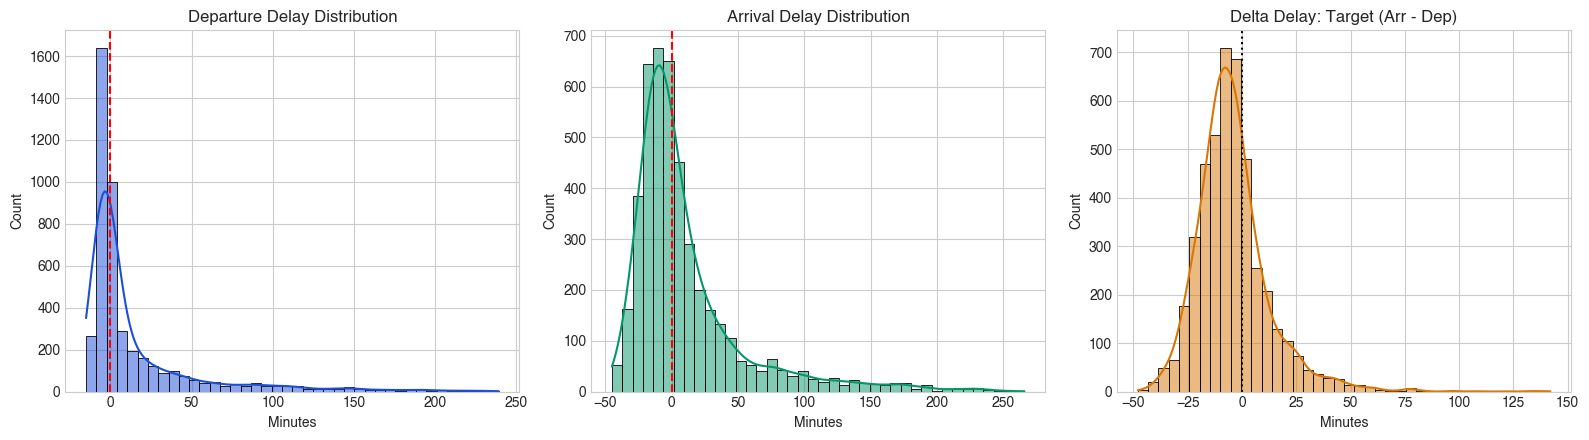

In [6]:
clean_sample = joined_df[(joined_df['DepDelay'] >= -30) & (joined_df['DepDelay'] <= 240) &
                         (joined_df['ArrDelay'] >= -45) & (joined_df['ArrDelay'] <= 300)].copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(clean_sample['DepDelay'], bins=40, kde=True, ax=axes[0], color='#1d4ed8')
axes[0].set_title('Departure Delay Distribution', fontweight='bold')
axes[0].set_xlabel('Minutes')
axes[0].axvline(0, color='red', linestyle='--')

sns.histplot(clean_sample['ArrDelay'], bins=40, kde=True, ax=axes[1], color='#059669')
axes[1].set_title('Arrival Delay Distribution', fontweight='bold')
axes[1].set_xlabel('Minutes')
axes[1].axvline(0, color='red', linestyle='--')

sns.histplot(clean_sample['delta_delay'], bins=40, kde=True, ax=axes[2], color='#d97706')
axes[2].set_title('Delta Delay: Target (Arr - Dep)', fontweight='bold')
axes[2].set_xlabel('Minutes')
axes[2].axvline(0, color='black', linestyle=':')

plt.tight_layout()
plt.show()


### 6.2. Destination Wind Speed vs. Airborne Delay Progression

/var/folders/7s/nsfv07ls25b817hv4_xg03s40000gn/T/ipykernel_4826/393218775.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='wind_bin', y='delta_delay', data=valid_weather, palette='Blues', showfliers=False)


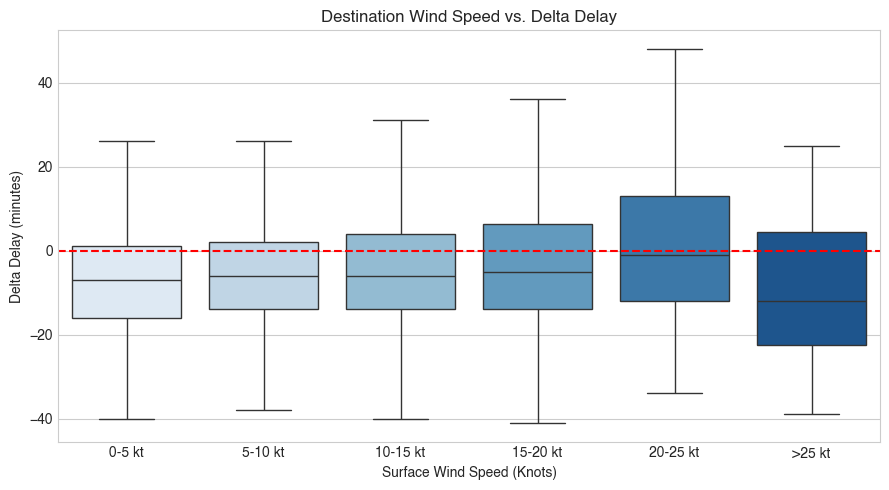

In [7]:
valid_weather = clean_sample.dropna(subset=['wind_speed_mps', 'delta_delay']).copy()
valid_weather['wind_speed_knots'] = valid_weather['wind_speed_mps'] * 1.94384
valid_weather['wind_bin'] = pd.cut(valid_weather['wind_speed_knots'], bins=[0, 5, 10, 15, 20, 25, 40],
                                   labels=['0-5 kt', '5-10 kt', '10-15 kt', '15-20 kt', '20-25 kt', '>25 kt'])

plt.figure(figsize=(9, 5))
sns.boxplot(x='wind_bin', y='delta_delay', data=valid_weather, palette='Blues', showfliers=False)
plt.title('Destination Wind Speed vs. Delta Delay', fontweight='bold')
plt.xlabel('Surface Wind Speed (Knots)')
plt.ylabel('Delta Delay (minutes)')
plt.axhline(0, color='red', linestyle='--')
plt.tight_layout()
plt.show()


### 6.3. Destination Visibility Degradation vs. Arrival Delay

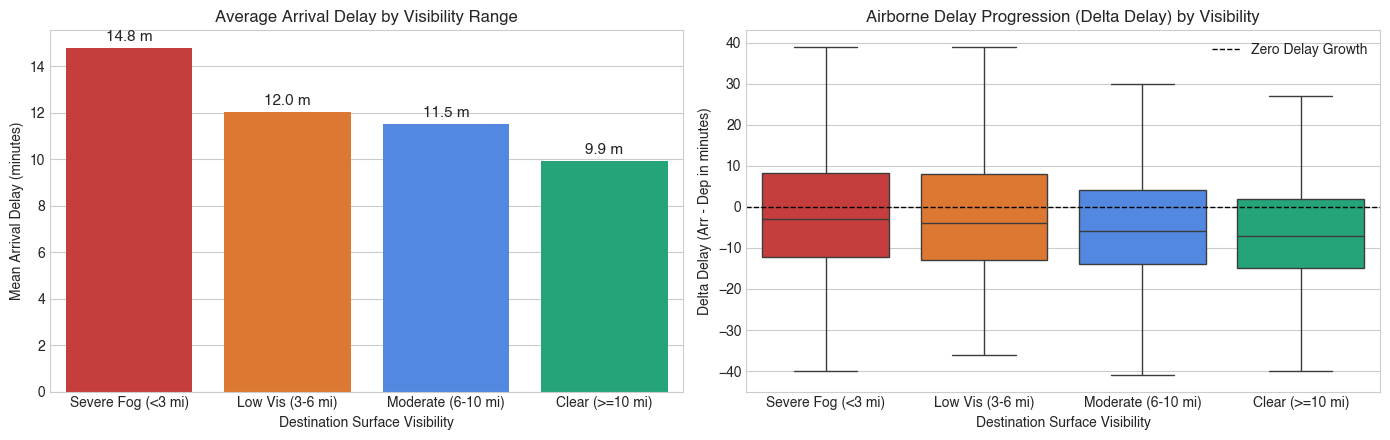

In [8]:
vis_sample = clean_sample.dropna(subset=['visibility_m']).copy()
vis_sample['visibility_miles'] = vis_sample['visibility_m'] / 1609.34
vis_sample['vis_category'] = pd.cut(
    vis_sample['visibility_miles'],
    bins=[-0.1, 3.0, 6.0, 9.9, 100.0],
    labels=['Severe Fog (<3 mi)', 'Low Vis (3-6 mi)', 'Moderate (6-10 mi)', 'Clear (>=10 mi)']
)

summary = vis_sample.groupby('vis_category', observed=False).agg(
    mean_ArrDelay=('ArrDelay', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
palette = ['#dc2626', '#f97316', '#3b82f6', '#10b981']

# Subplot 3A: Mean Arrival Delay
sns.barplot(x='vis_category', y='mean_ArrDelay', data=summary, ax=axes[0], palette=palette, hue='vis_category', legend=False)
axes[0].set_title('Average Arrival Delay by Visibility Range', fontweight='bold')
axes[0].set_xlabel('Destination Surface Visibility')
axes[0].set_ylabel('Mean Arrival Delay (minutes)')
for i, v in enumerate(summary['mean_ArrDelay']):
    axes[0].text(i, v + 0.3, f'{v:.1f} m', ha='center', fontweight='bold', fontsize=11)

# Subplot 3B: Delta Delay Progression Boxplot
sns.boxplot(x='vis_category', y='delta_delay', data=vis_sample, ax=axes[1], palette=palette, hue='vis_category', showfliers=False)
axes[1].set_title('Airborne Delay Progression (Delta Delay) by Visibility', fontweight='bold')
axes[1].set_xlabel('Destination Surface Visibility')
axes[1].set_ylabel('Delta Delay (Arr - Dep in minutes)')
axes[1].axhline(0, color='black', linestyle='--', linewidth=1, label='Zero Delay Growth')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


### 6.4. Hourly Congestion Curve: Flight Volume vs. Departure Delay

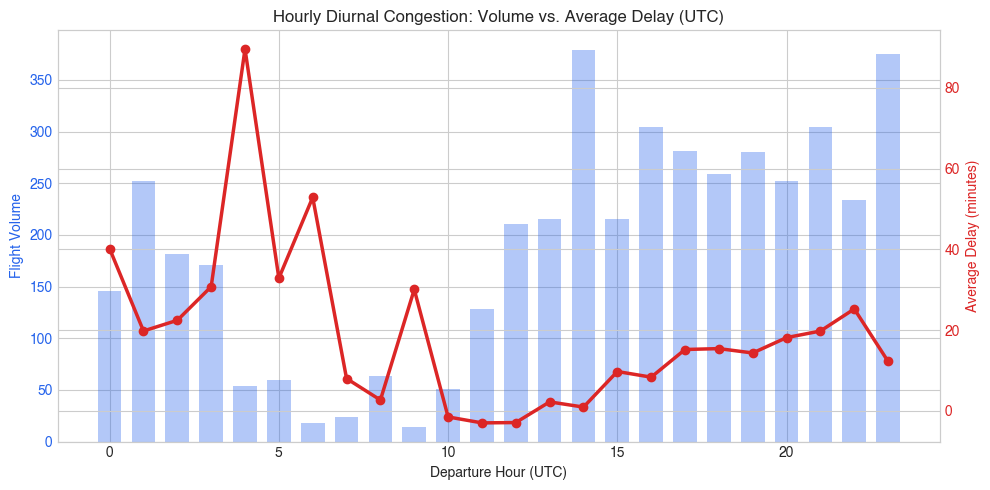

In [9]:
clean_sample['dep_hour'] = clean_sample['wheels_off_utc'].dt.hour
hourly_stats = clean_sample.groupby('dep_hour').agg(
    flight_count=('FlightDate', 'count'),
    avg_dep_delay=('DepDelay', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))
color1 = '#2563eb'
ax1.set_xlabel('Departure Hour (UTC)', fontweight='bold')
ax1.set_ylabel('Flight Volume', color=color1, fontweight='bold')
ax1.bar(hourly_stats['dep_hour'], hourly_stats['flight_count'], color=color1, alpha=0.35, width=0.7)
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()
color2 = '#dc2626'
ax2.set_ylabel('Average Delay (minutes)', color=color2, fontweight='bold')
ax2.plot(hourly_stats['dep_hour'], hourly_stats['avg_dep_delay'], color=color2, marker='o', linewidth=2.5)
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Hourly Diurnal Congestion: Volume vs. Average Delay (UTC)', fontweight='bold')
plt.tight_layout()
plt.show()


### 6.5. Inbound Congestion Comparison Across Major Hubs

/var/folders/7s/nsfv07ls25b817hv4_xg03s40000gn/T/ipykernel_4826/241289384.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Dest', y='inbound_volume', data=hub_metrics, ax=axes[0], palette='crest')
/var/folders/7s/nsfv07ls25b817hv4_xg03s40000gn/T/ipykernel_4826/241289384.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Dest', y='pct_delayed', data=hub_metrics, ax=axes[1], palette='flare')


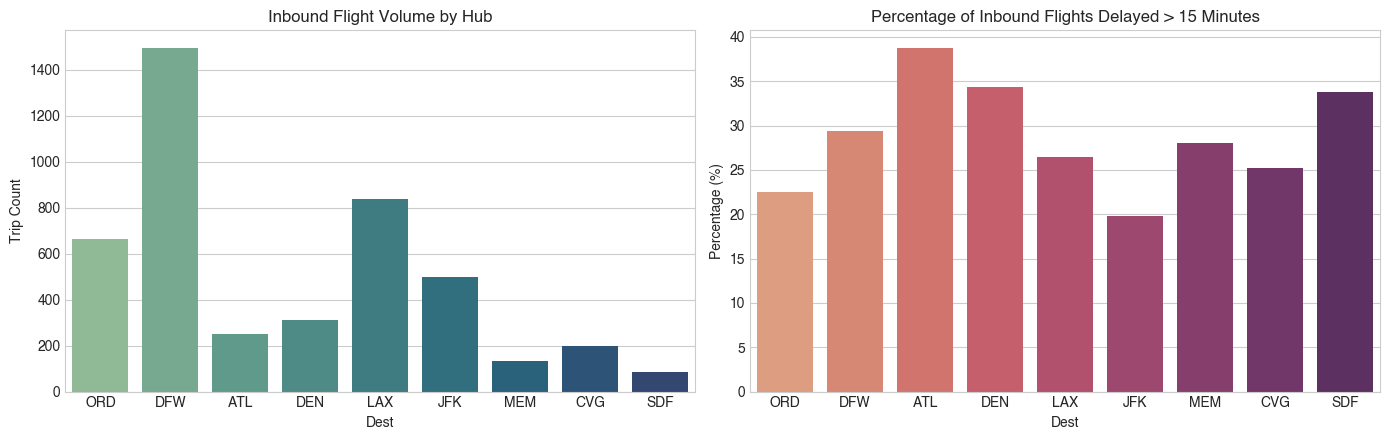

In [10]:
top_hubs = ['ORD', 'DFW', 'ATL', 'DEN', 'LAX', 'JFK', 'MEM', 'CVG', 'SDF']
hub_sample = clean_sample[clean_sample['Dest'].isin(top_hubs)].copy()
hub_metrics = hub_sample.groupby('Dest').agg(
    inbound_volume=('FlightDate', 'count'),
    pct_delayed=('ArrDelay', lambda x: (x > 15).mean() * 100)
).reindex(top_hubs).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x='Dest', y='inbound_volume', data=hub_metrics, ax=axes[0], palette='crest')
axes[0].set_title('Inbound Flight Volume by Hub', fontweight='bold')
axes[0].set_ylabel('Trip Count')

sns.barplot(x='Dest', y='pct_delayed', data=hub_metrics, ax=axes[1], palette='flare')
axes[1].set_title('Percentage of Inbound Flights Delayed > 15 Minutes', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')

plt.tight_layout()
plt.show()


## 7. Key Findings & Parquet Export
1. **Target Formulation Validation:** While `DepDelay` and `ArrDelay` span broad ranges, $\Delta	ext{delay}$ centers tightly around 0 with a slight left-skew (tailwinds) and significant right-tail expansion (weather holding patterns).
2. **Weather Sensitivity:** Higher surface winds (> 20 knots) and low surface visibility (< 3 miles) correlate directly with increased arrival delay and positive delay growth.
3. **Diurnal Peaks:** Delay risk climbs consistently from afternoon through evening UTC hours, aligning with hub flight stacking.
